In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
arquivo = files.upload()

Saving clara.png to clara.png
Saving escura.png to escura.png
Saving normal.png to normal.png


In [3]:
img_normal = cv2.imread('normal.png', cv2.IMREAD_COLOR_RGB)

img_clara = cv2.imread('clara.png', cv2.IMREAD_COLOR_RGB)

img_escura = cv2.imread('escura.png', cv2.IMREAD_COLOR_RGB)

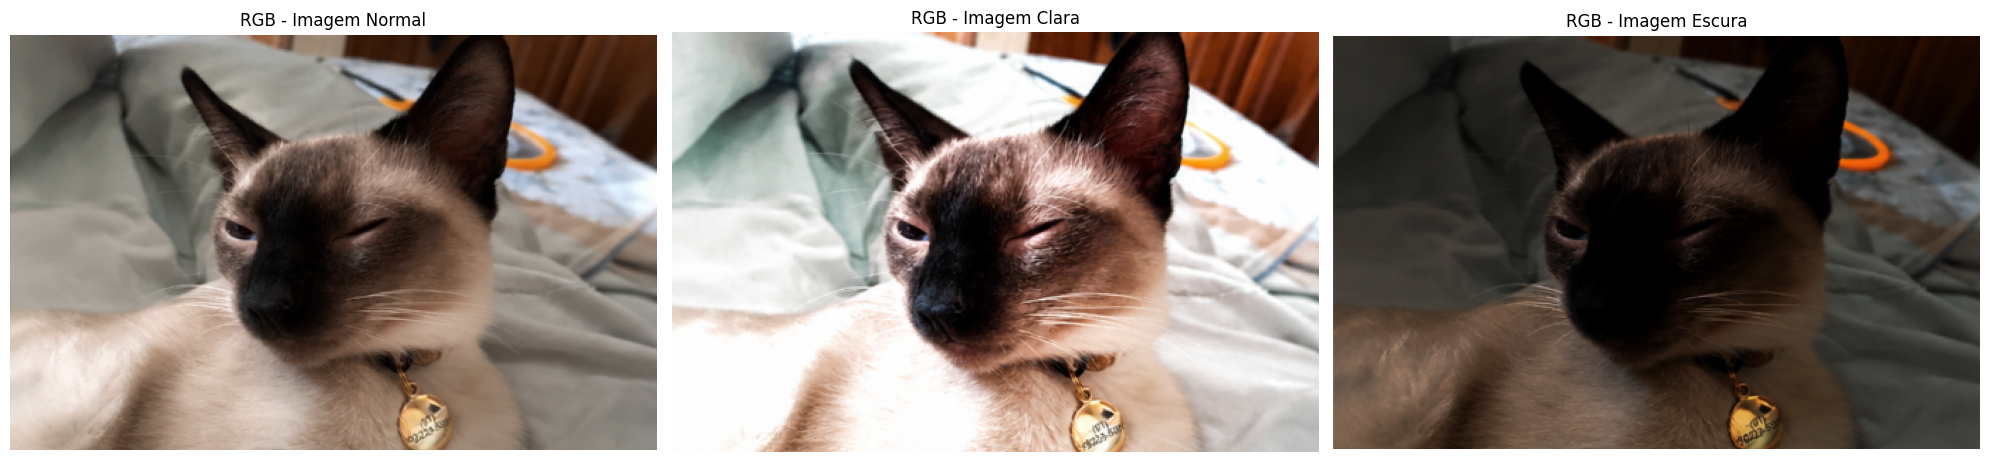

In [4]:
fig, ax = plt.subplots(1,3, figsize=(20,15))

ax[0].imshow(img_normal)
ax[0].set_title('RGB - Imagem Normal')
ax[0].axis('off')

ax[1].imshow(img_clara)
ax[1].set_title('RGB - Imagem Clara')
ax[1].axis('off')

ax[2].imshow(img_escura)
ax[2].set_title('RGB - Imagem Escura')
ax[2].axis('off')

plt.tight_layout()
plt.show()

# 1. Converta

In [5]:
img_normal_gray = cv2.cvtColor(img_normal, cv2.COLOR_RGB2GRAY)

img_clara_gray = cv2.cvtColor(img_clara, cv2.COLOR_RGB2GRAY)

img_escura_gray = cv2.cvtColor(img_escura, cv2.COLOR_RGB2GRAY)

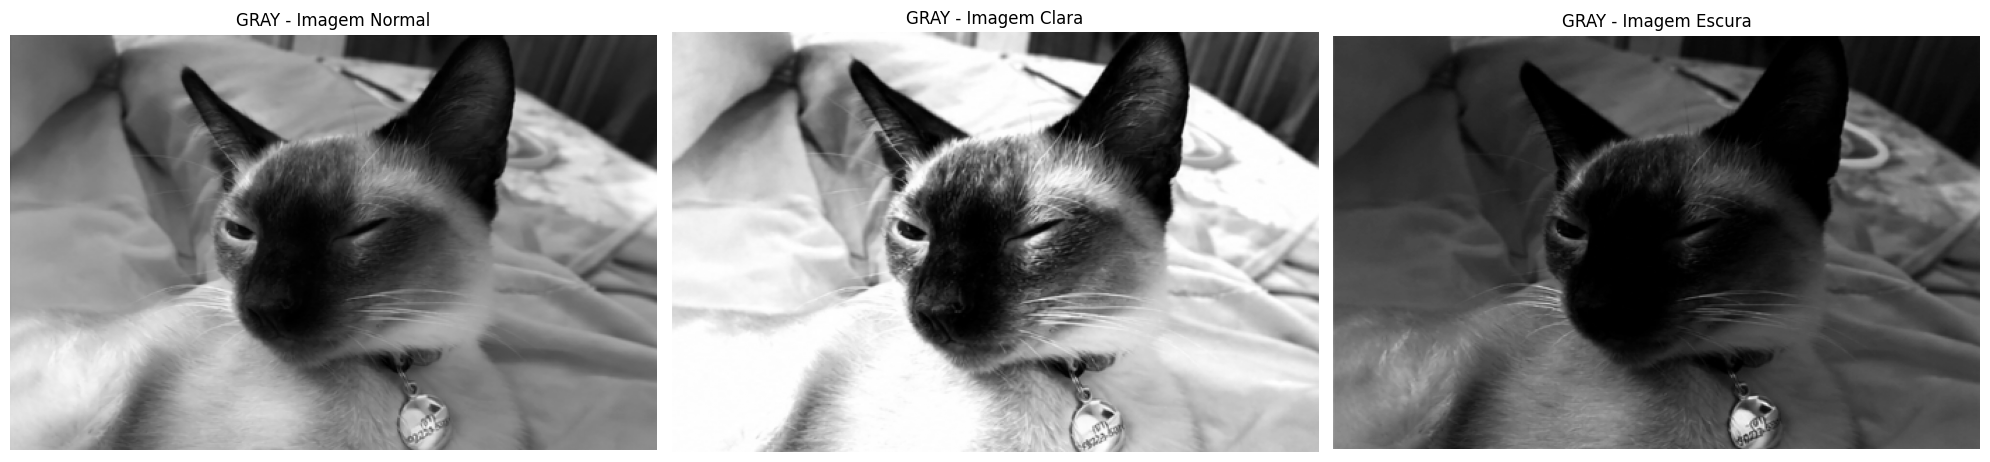

In [6]:
fig, ax = plt.subplots(1,3, figsize=(20,15))

ax[0].imshow(img_normal_gray, cmap='gray')
ax[0].set_title('GRAY - Imagem Normal')
ax[0].axis('off')

ax[1].imshow(img_clara_gray, cmap='gray')
ax[1].set_title('GRAY - Imagem Clara')
ax[1].axis('off')

ax[2].imshow(img_escura_gray, cmap='gray')
ax[2].set_title('GRAY - Imagem Escura')
ax[2].axis('off')

plt.tight_layout()
plt.show()

In [7]:
def calcHist(img, ax):
    hist_arr = np.zeros(256, dtype=int)

    for px in img:
        hist_arr[px] += 1

    ax.bar(range(256), hist_arr)

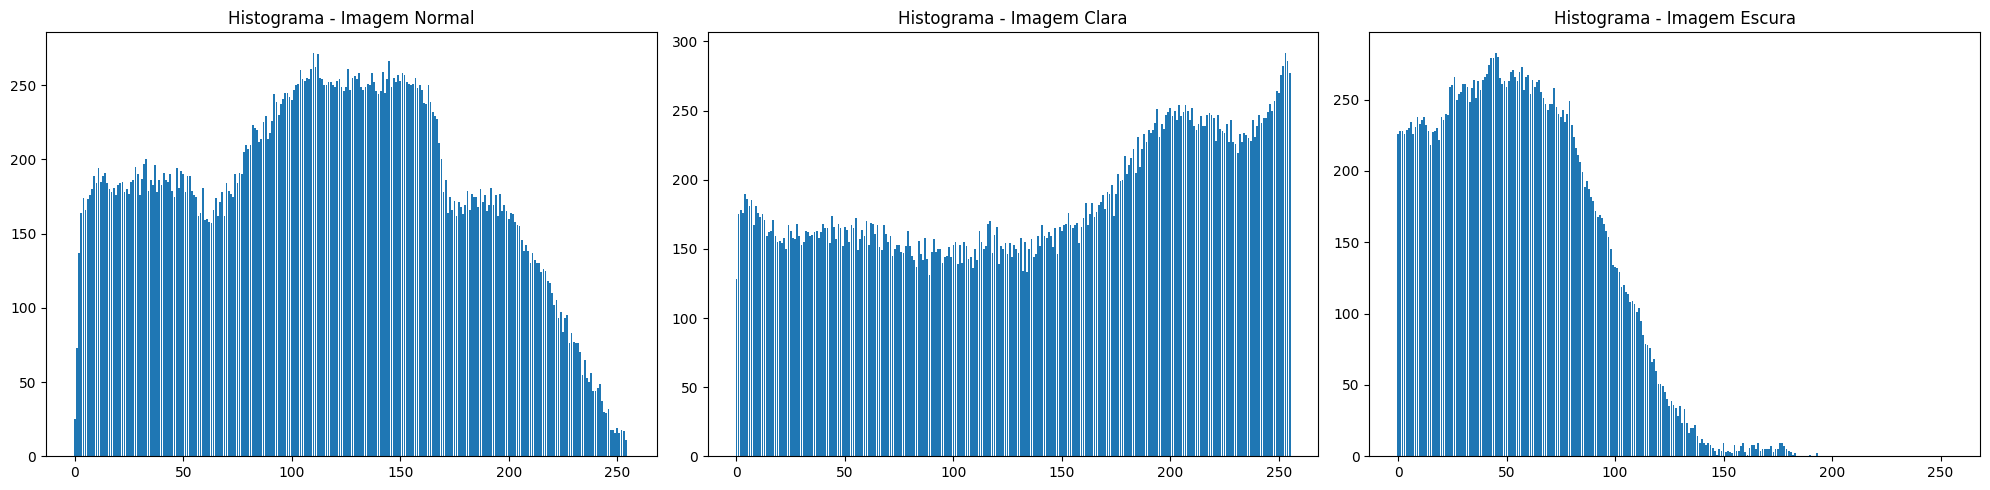

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

calcHist(img_normal_gray, ax[0])
ax[0].set_title('Histograma - Imagem Normal')

calcHist(img_clara_gray, ax[1])
ax[1].set_title('Histograma - Imagem Clara')

calcHist(img_escura_gray, ax[2])
ax[2].set_title('Histograma - Imagem Escura')

plt.tight_layout()
plt.show()

# 2. Escreva

### Em que faixa as intensidades estão concentradas e o que isso indica sobre a imagem.

O histograma da imagem normal apresenta intensidades distribuídas principalmente entre (50 e 200) níveis de cinza, indicando uma boa variação tonal e contraste equilibrado.

A imagem clara possui maior concentração nas intensidades altas (150 a 255), indicando maior luminosidade, enquanto a imagem escura concentra os pixels em valores baixos (0 a 150), indicando predominância de sombras e baixa iluminação.

# 3. Escolha

In [9]:
def equalizacao_histograma_manual(imagem):

    histograma = np.zeros(256, dtype=int)

    # Calcula o histograma
    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            nivel = imagem[i, j]
            histograma[nivel] += 1

    # Calcula a distribuição acumulada (CDF)
    cdf = np.cumsum(histograma)

    # Normaliza a CDF para o intervalo [0, 255]
    cdf_normalizada = 255 * cdf / cdf[-1]

    resultado = np.zeros_like(imagem)

    # Substitui cada pixel pelo novo nível de cinza
    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            resultado[i, j] = cdf_normalizada[imagem[i, j]]

    return resultado.astype(np.uint8)

Operação escolhida: Equalização de Histograma

Foi escolhida para melhorar o contraste da imagem por meio da redistribuição dos níveis de cinza, destacando detalhes em regiões com pouca variação de intensidade.

Parâmetro utilizado: CDF (Função de Distribuição Acumulada) normalizada no intervalo 0 a 255.

Não utiliza parâmetros (L e H) ou γ.

In [10]:
normal_equalizacao = equalizacao_histograma_manual(img_normal_gray)
clara_equalizacao = equalizacao_histograma_manual(img_clara_gray)
escura_equalizacao = equalizacao_histograma_manual(img_escura_gray)

# 4. Monte

Text(0.5, 1.0, 'Equalizado - Histograma')

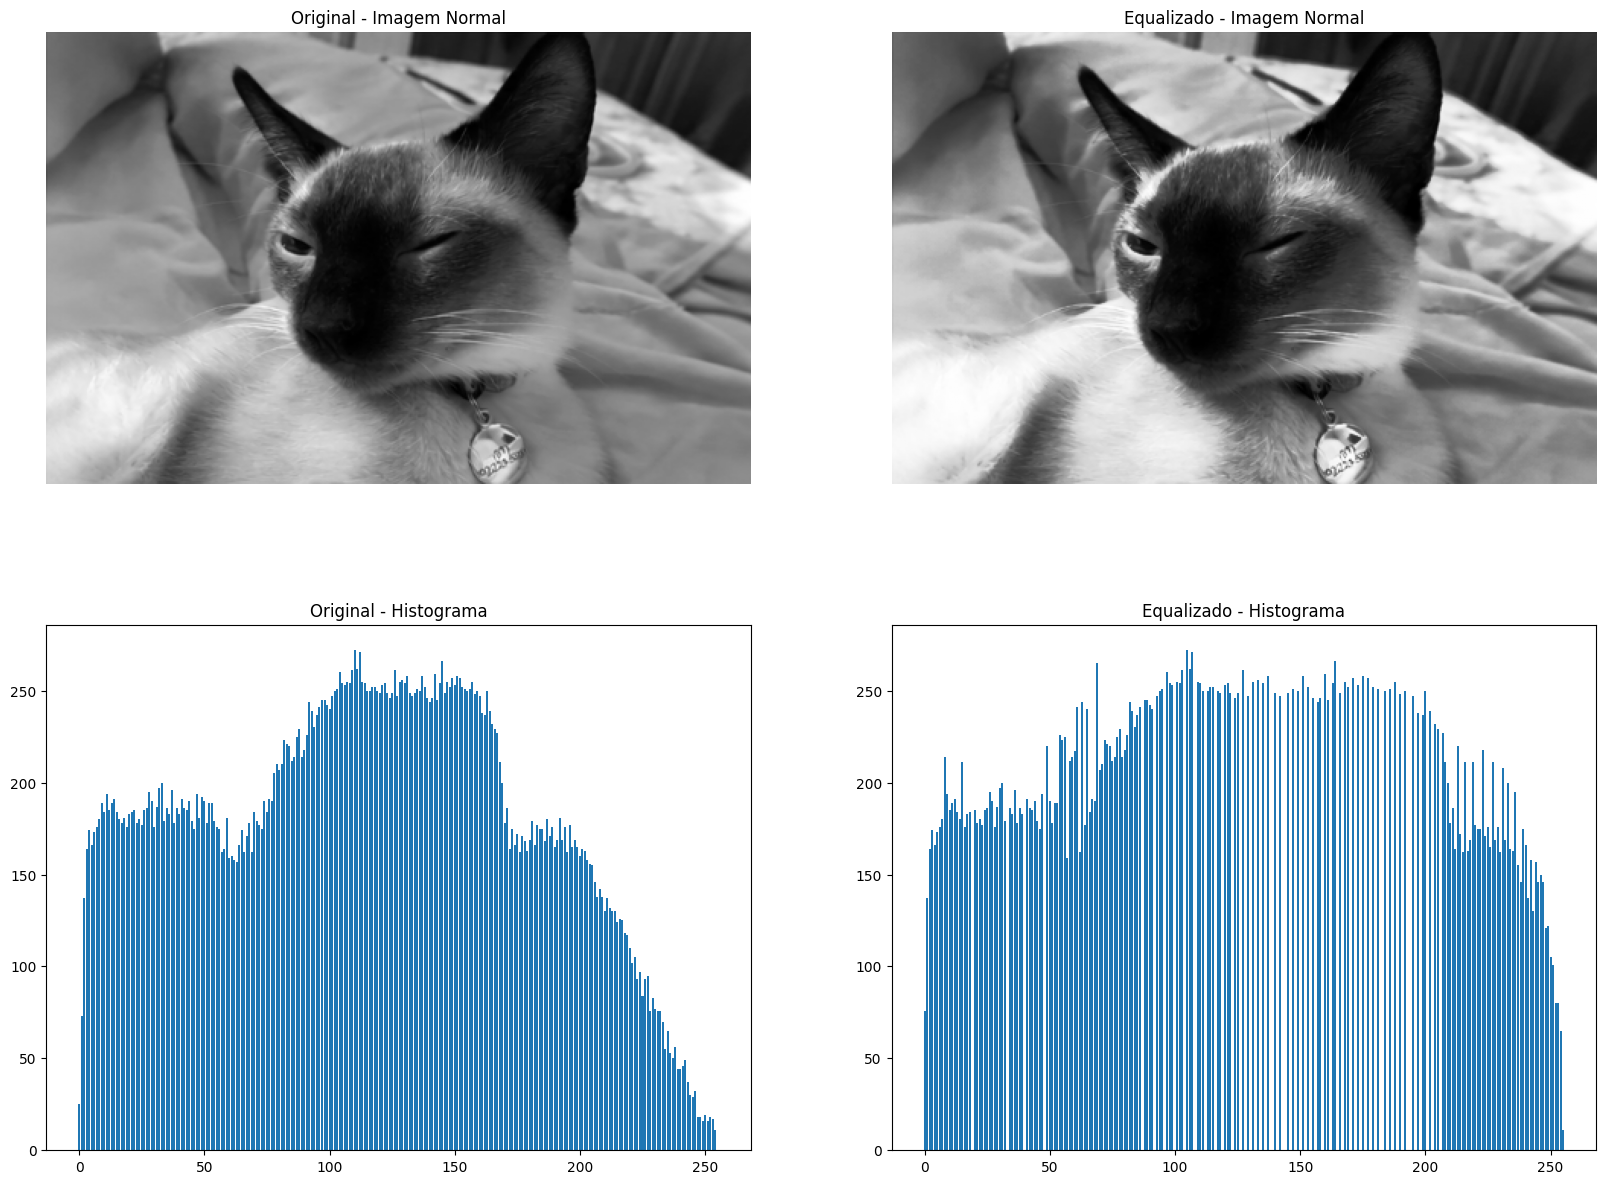

In [11]:
fig, ax = plt.subplots(2,2, figsize=(20,15))

ax[0,0].imshow(img_normal_gray, cmap='gray')
ax[0,0].set_title('Original - Imagem Normal')
ax[0,0].axis('off')

calcHist(img_normal_gray, ax[1,0])
ax[1,0].set_title('Original - Histograma')

ax[0,1].imshow(normal_equalizacao, cmap='gray')
ax[0,1].set_title('Equalizado - Imagem Normal')
ax[0,1].axis('off')

calcHist(normal_equalizacao, ax[1,1])
ax[1,1].set_title('Equalizado - Histograma')

Text(0.5, 1.0, 'Equalizado - Histograma')

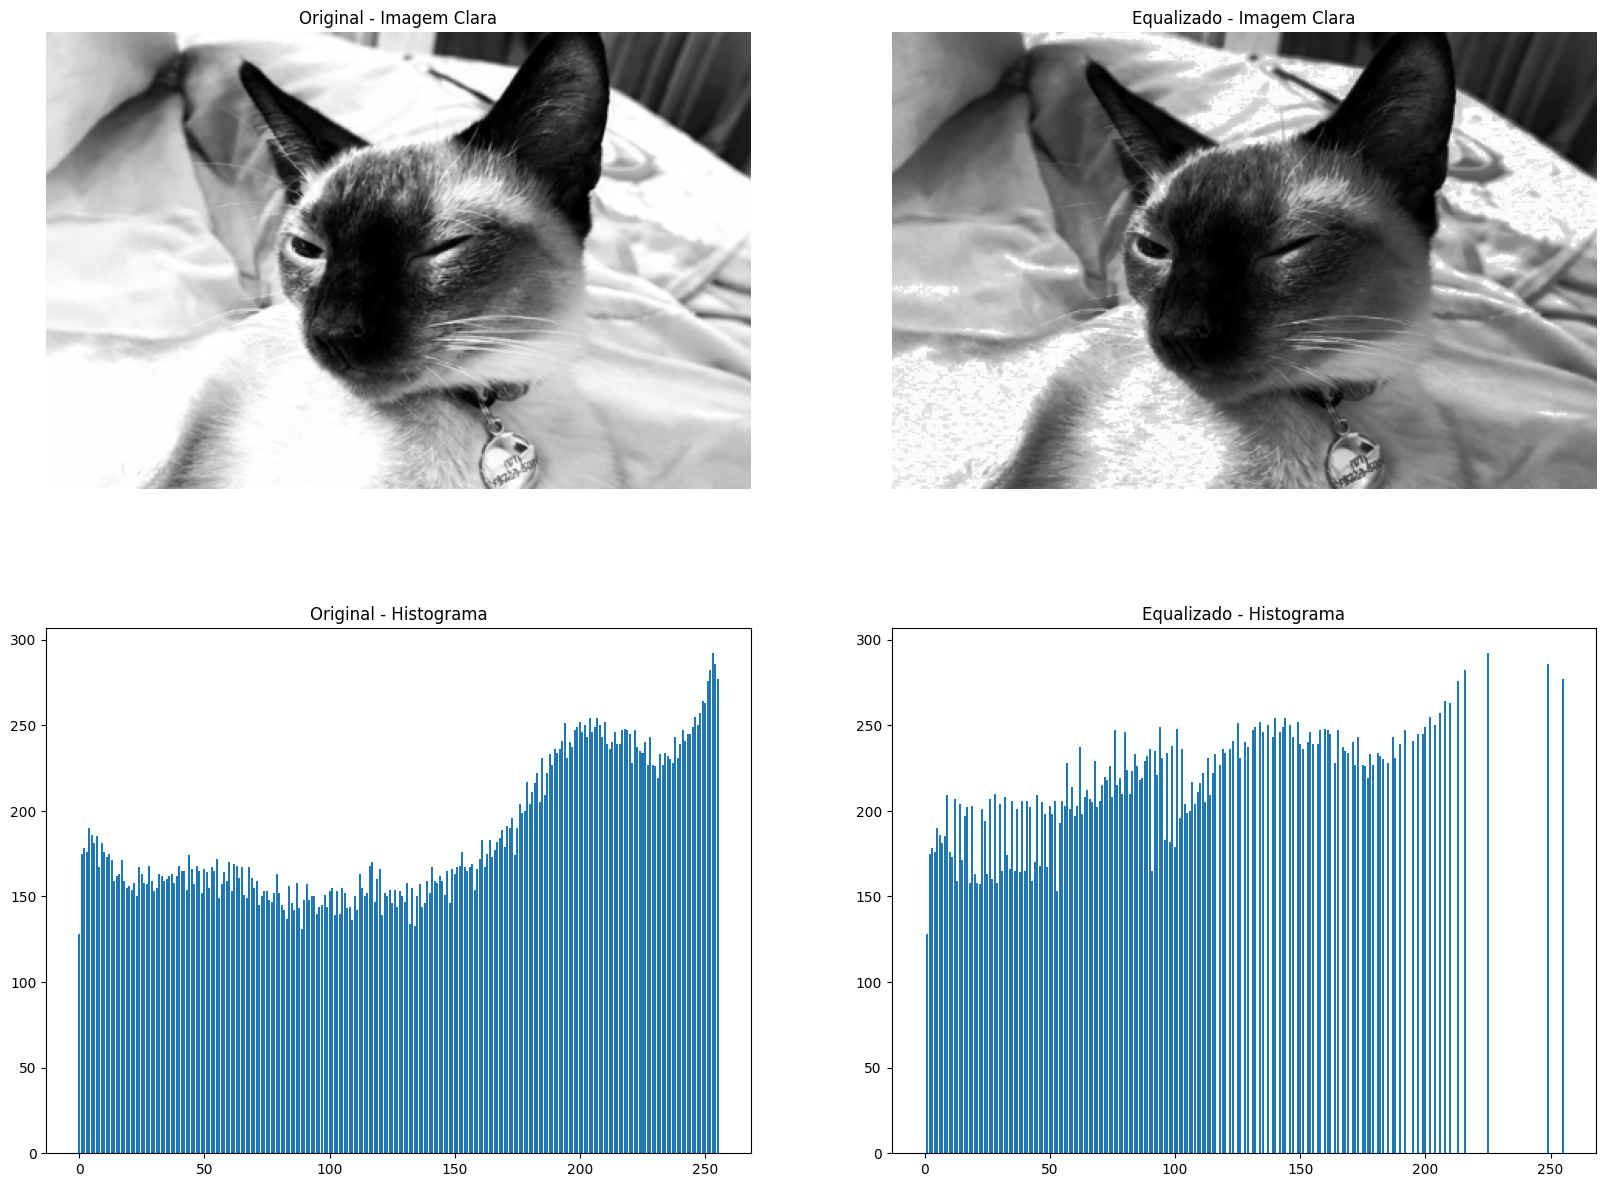

In [12]:
fig, ax = plt.subplots(2,2, figsize=(20,15))

ax[0,0].imshow(img_clara_gray, cmap='gray')
ax[0,0].set_title('Original - Imagem Clara')
ax[0,0].axis('off')

calcHist(img_clara_gray, ax[1,0])
ax[1,0].set_title('Original - Histograma')

ax[0,1].imshow(clara_equalizacao, cmap='gray')
ax[0,1].set_title('Equalizado - Imagem Clara')
ax[0,1].axis('off')

calcHist(clara_equalizacao, ax[1,1])
ax[1,1].set_title('Equalizado - Histograma')

Text(0.5, 1.0, 'Equalizado - Histograma')

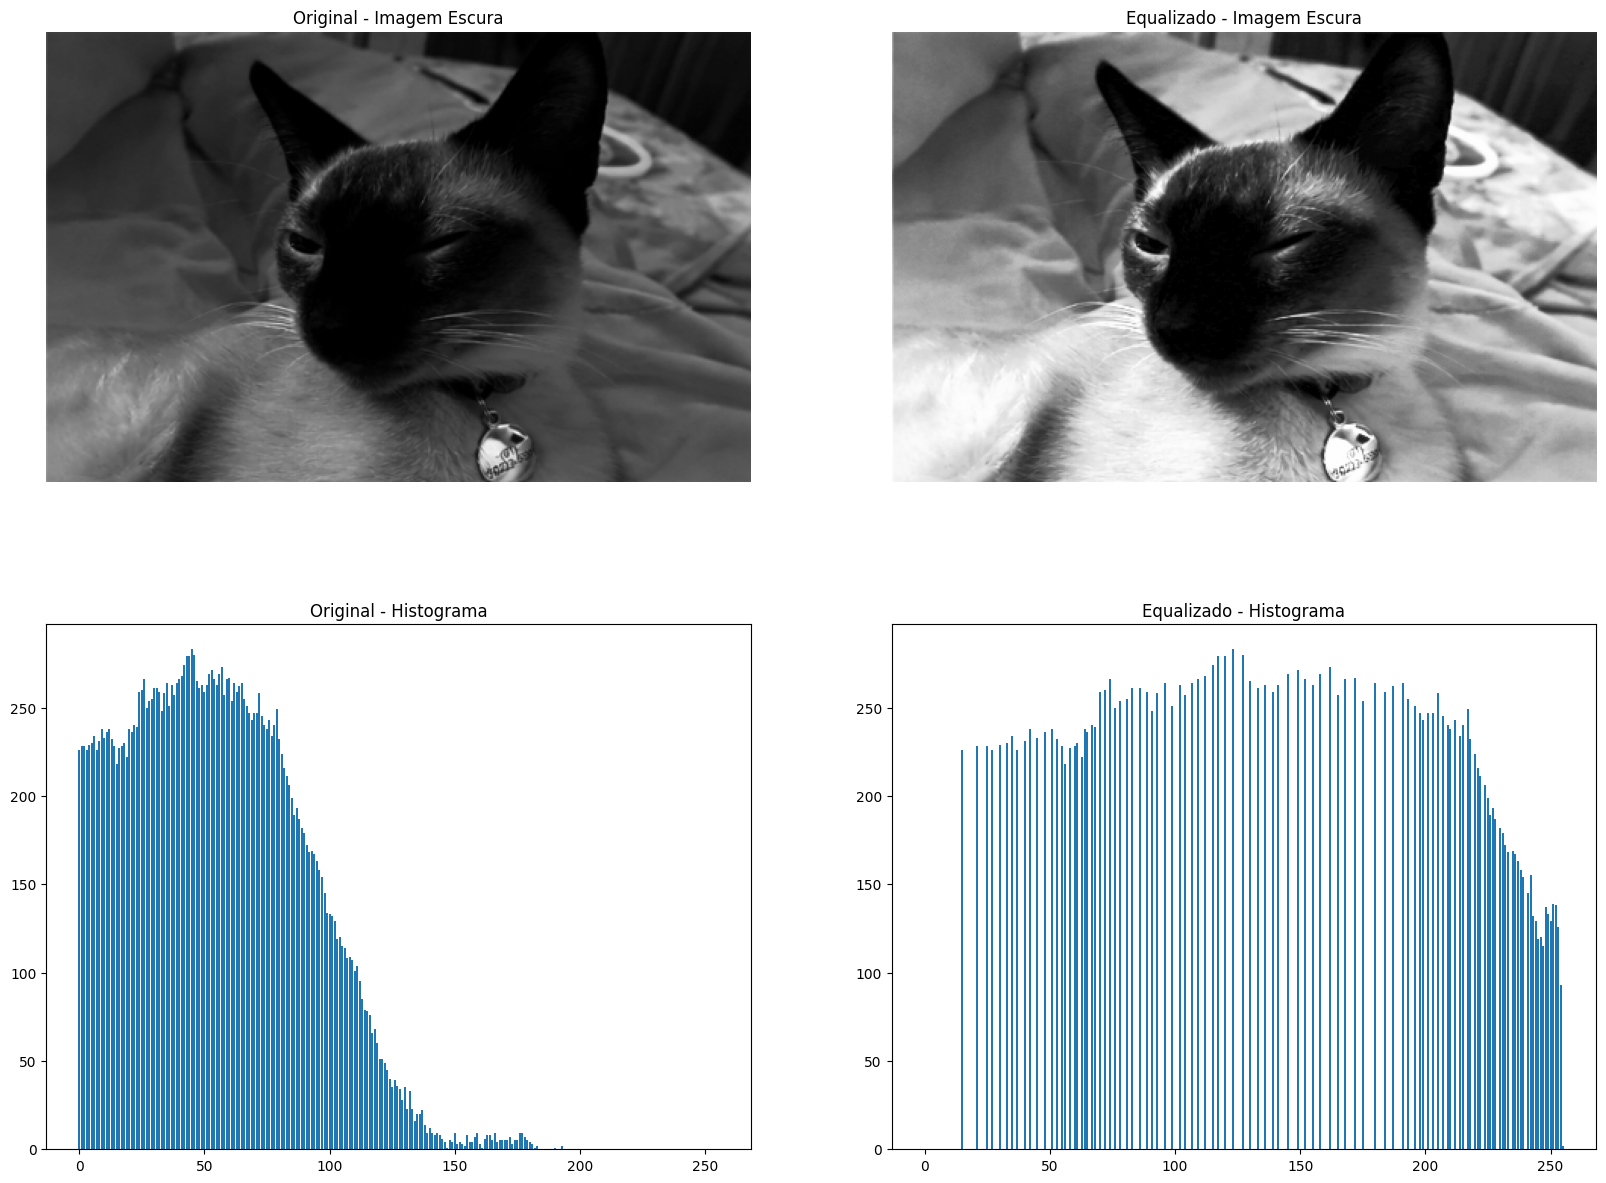

In [13]:
fig, ax = plt.subplots(2,2, figsize=(20,15))

ax[0,0].imshow(img_escura_gray, cmap='gray')
ax[0,0].set_title('Original - Imagem Escura')
ax[0,0].axis('off')

calcHist(img_escura_gray, ax[1,0])
ax[1,0].set_title('Original - Histograma')

ax[0,1].imshow(escura_equalizacao, cmap='gray')
ax[0,1].set_title('Equalizado - Imagem Escura')
ax[0,1].axis('off')

calcHist(escura_equalizacao, ax[1,1])
ax[1,1].set_title('Equalizado - Histograma')

### Em qual das três imagens a operação fez menos diferença? Por quê?


A operação fez menos diferença na imagem normal, pois ela já apresentava uma distribuição equilibrada dos níveis de cinza e um contraste adequado. Como os pixels já ocupavam uma faixa ampla de intensidades, a equalização do histograma causou apenas pequenas alterações visuais, enquanto nas imagens clara e escura houve maior impacto, pois os níveis de intensidade estavam mais concentrados e a técnica conseguiu redistribuí-los, aumentando o contraste e destacando detalhes.